In [25]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay



raw =pd.read_csv("../../data/english_transactions_quality_500.csv")
print("Original shape:", raw.shape)
print(raw.columns.tolist())
display(raw.head())

Original shape: (500, 7)
['description', 'type', 'category', 'scenario_id', 'template_family', 'language', 'source']


,description,type,category,scenario_id,template_family,language,source
0,LE 650 gone on trainers at the shoe stall; I h...,Expense,Shopping,shopping.clothing_accessories,amount_led,English,synthetic
1,My prescribed physical rehabilitation session ...,Expense,Healthcare,healthcare.care_consultation,passive_settlement,English,synthetic
2,Buying fresh fruit at the market used 120 EGP ...,Expense,Groceries,groceries.fresh_ingredients,financial_effect,English,synthetic
3,Rent on my small residential house in Tanta ha...,Income,Rental Income,rental_income.residential,passive_settlement,English,synthetic
4,"Looking back at this week, I collected just my...",Income,Salary,salary.employee_base_pay,retrospective_completion,English,synthetic


## 1. Data quality and taxonomy checks

In [26]:
required = ["description", "type", "category"]
assert set(required).issubset(raw.columns), f"Missing required columns: {set(required)-set(raw.columns)}"
df = raw.copy()
for col in required:
    df[col] = df[col].astype('string').str.strip()
    df.loc[df[col].eq(''), col] = pd.NA
print("Missing values:", df[required].isna().sum().to_dict())
df = df.dropna(subset=required).copy()
df = df[df['type'].isin(['Income', 'Expense'])].copy()
# When identical text is assigned contradictory labels, remove those rows for review instead of keeping an arbitrary label.
conflicting = df.groupby('description').agg(types=('type','nunique'), cats=('category','nunique'))
conflict_texts = set(conflicting.index[(conflicting.types > 1) | (conflicting.cats > 1)])
print("Conflicting-description groups removed:", len(conflict_texts))
df = df[~df.description.isin(conflict_texts)].drop_duplicates(subset=['description']).reset_index(drop=True)
print("Cleaned shape:", df.shape)
print("Type counts:\n", df.type.value_counts())
print("Category counts:\n", df.category.value_counts())

# A category must belong to exactly one type for the hierarchical design to be valid.
taxonomy = df.groupby('category')['type'].nunique()
assert taxonomy.max() == 1, 'Some categories map to both Income and Expense. Review the taxonomy first.'
print("Category → type mapping:\n", df.groupby('category')['type'].first().sort_index())

Missing values: {'description': 0, 'type': 0, 'category': 0}
Conflicting-description groups removed: 0
Cleaned shape: (500, 7)
Type counts:
 type
Expense    250
Income     250
Name: count, dtype: Int64
Category counts:
 category
Rental Income        50
Salary               50
Business Income      50
Gifts                50
Freelance            50
Shopping             32
Food & Dining        32
Healthcare           31
Groceries            31
Bills & Utilities    31
Entertainment        31
Education            31
Transportation       31
Name: count, dtype: Int64
Category → type mapping:
 category
Bills & Utilities    Expense
Business Income       Income
Education            Expense
Entertainment        Expense
Food & Dining        Expense
Freelance             Income
Gifts                 Income
Groceries            Expense
Healthcare           Expense
Rental Income         Income
Salary                Income
Shopping             Expense
Transportation       Expense
Name: type, dtype: st

## 2. Single holdout split, shared by all three models

We stratify by category. Each category belongs to only one type, so this also preserves the two type distributions approximately. Keep the test set untouched while refining the model.

In [27]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df['category'])
train_df = train_df.copy()
test_df = test_df.copy()
print('Train:', len(train_df), 'Test:', len(test_df))
print('Train types:', train_df.type.value_counts().to_dict())
print('Test types:', test_df.type.value_counts().to_dict())

Train: 400 Test: 100
Train types: {'Income': 200, 'Expense': 200}
Test types: {'Income': 50, 'Expense': 50}


## 3. Train type classifier and separate income/expense category classifiers

In [ ]:
def build_model():
    return Pipeline([
        ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(2, 5), sublinear_tf=True)),
        ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
    ])

type_model = build_model()
type_model.fit(train_df.description, train_df.type)

expense_train = train_df[train_df.type == 'Expense']
income_train = train_df[train_df.type == 'Income']

expense_category_model = build_model()
expense_category_model.fit(expense_train.description, expense_train.category)

income_category_model = build_model()
income_category_model.fit(income_train.description, income_train.category)

print('Models fitted: 1 type classifier + 2 type-specific category classifiers')
print('Expense categories:', expense_category_model.classes_.tolist())
print('Income categories:', income_category_model.classes_.tolist())

Models fitted: 1 type classifier + 2 type-specific category classifiers
Expense categories: ['Bills & Utilities', 'Education', 'Entertainment', 'Food & Dining', 'Groceries', 'Healthcare', 'Shopping', 'Transportation']
Income categories: ['Business Income', 'Freelance', 'Gifts', 'Rental Income', 'Salary']


## 4. Hierarchical prediction

**Important:** The category model is selected by the *predicted* type, **not** by the actual type. Otherwise the end-to-end evaluation would be artificially optimistic.

In [35]:
def predict_hierarchical(texts):
    texts = pd.Series(list(texts), dtype='string').fillna('').astype(str)
    predicted_types = type_model.predict(texts)
    predicted_categories = np.empty(len(texts), dtype=object)
    expense_mask = predicted_types == 'Expense'
    income_mask = predicted_types == 'Income'
    if expense_mask.any():
        predicted_categories[expense_mask] = expense_category_model.predict(texts[expense_mask])
    if income_mask.any():
        predicted_categories[income_mask] = income_category_model.predict(texts[income_mask])
    return pd.DataFrame({'description': texts.to_numpy(), 'predicted_type': predicted_types,
                         'predicted_category': predicted_categories})

pred = predict_hierarchical(test_df.description)
assert len(pred) == len(test_df)
display(pred.head())

,description,predicted_type,predicted_category
0,The clinic paid me 14000 EGP under my employme...,Income,Salary
1,The day's sales at my bookshop left the busine...,Income,Business Income
2,Last night I bought a chargre from the mobile-...,Expense,Groceries
3,My contracted staff wages at the veterinary pr...,Income,Salary
4,Over the weekend my client settled my freelanc...,Income,Freelance


## 5. Evaluate each task AND the full pipeline

,Task,Accuracy,Macro-F1
0,Type,0.96,0.959984
1,Category (end-to-end),0.73,0.683251
2,Joint type + category,0.73,NaN



TYPE REPORT
               precision    recall  f1-score   support

     Expense       0.98      0.94      0.96        50
      Income       0.94      0.98      0.96        50

    accuracy                           0.96       100
   macro avg       0.96      0.96      0.96       100
weighted avg       0.96      0.96      0.96       100


CATEGORY REPORT (routed predictions)
                    precision    recall  f1-score   support

Bills & Utilities       0.75      1.00      0.86         6
  Business Income       1.00      0.80      0.89        10
        Education       1.00      0.67      0.80         6
    Entertainment       0.50      0.67      0.57         6
    Food & Dining       0.60      0.43      0.50         7
        Freelance       0.77      1.00      0.87        10
            Gifts       1.00      1.00      1.00        10
        Groceries       0.33      0.33      0.33         6
       Healthcare       0.67      0.67      0.67         6
    Rental Income       0.91 

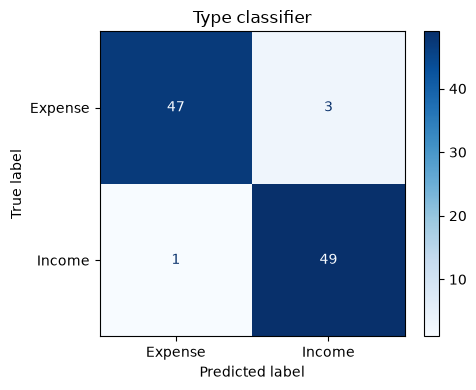

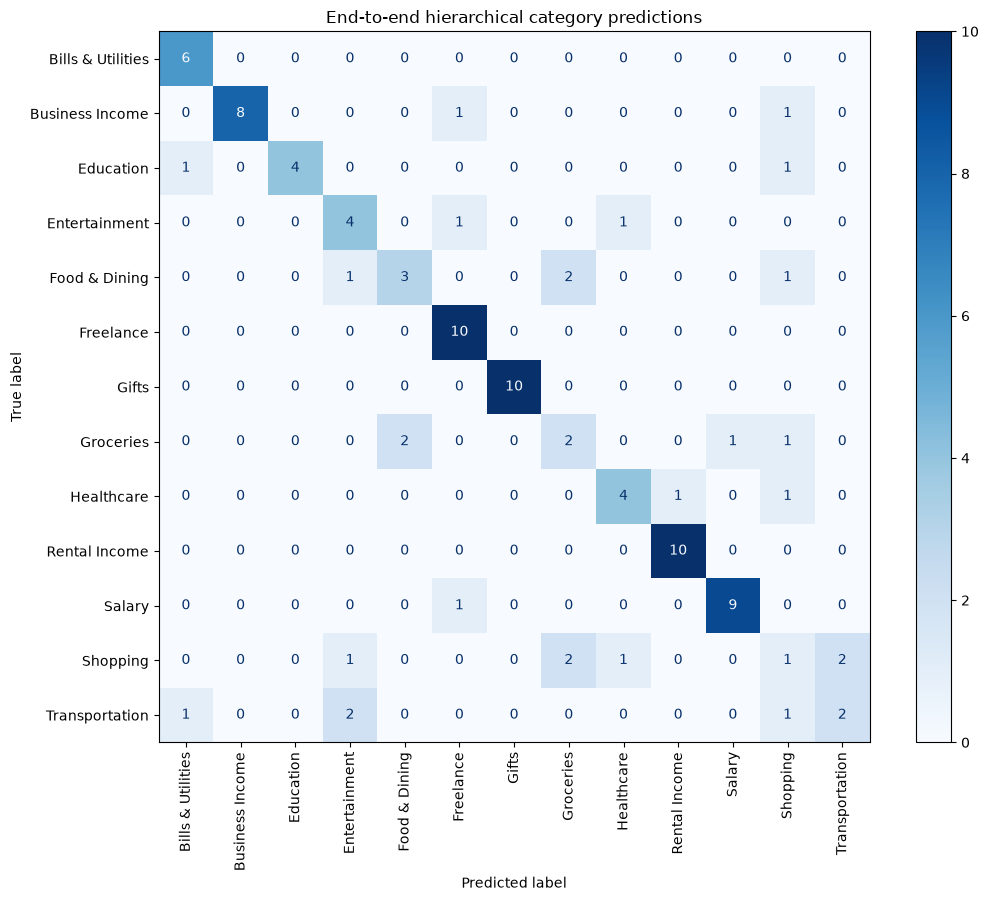

In [36]:
true_type = test_df.type.to_numpy()
true_category = test_df.category.to_numpy()
pred_type = pred.predicted_type.to_numpy()
pred_category = pred.predicted_category.to_numpy()

metrics = {
  'Type': (accuracy_score(true_type, pred_type), f1_score(true_type, pred_type, average='macro', zero_division=0)),
  'Category (end-to-end)': (accuracy_score(true_category, pred_category), f1_score(true_category, pred_category, average='macro', zero_division=0)),
  'Joint type + category': (np.mean((true_type == pred_type) & (true_category == pred_category)), None)
}
metrics_df = pd.DataFrame([{'Task': k, 'Accuracy': v[0], 'Macro-F1': v[1]} for k,v in metrics.items()])
display(metrics_df)
print('\nTYPE REPORT\n', classification_report(true_type, pred_type, zero_division=0))
print('\nCATEGORY REPORT (routed predictions)\n', classification_report(true_category, pred_category, zero_division=0))

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(true_type, pred_type, ax=ax, cmap='Blues')
ax.set_title('Type classifier')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(11,9))
ConfusionMatrixDisplay.from_predictions(true_category, pred_category, ax=ax, cmap='Blues', xticks_rotation=90)
ax.set_title('End-to-end hierarchical category predictions')
plt.tight_layout(); plt.show()

## 6. Manual stress test (diagnostic only)

Some inputs are out of scope for the current binary taxonomy: refunds, reimbursements, and money to be repaid. Do not count those as standard Income/Expense evaluation records without an explicit policy.

In [37]:
stress_sentences = [
    'I paid 1200 EGP for a new pair of sneakers',
    'The electricity bill cost me 650 pounds',
    'I earned 4500 EGP designing a website',
    'My landlord collected 3000 EGP from me',
    'I bought fresh vegetables for 250 EGP',
    'I paid 180 EGP for lunch at a restaurant',
    'I received 12000 EGP for renting out my apartment',
    'My dental appointment cost 700 EGP',
    'The bus ticket was 35 pounds',
    'I received 2000 EGP as a birthday gift',
    'I paid 900 EGP for my online university course',
    'I made 650 EGP from my freelance photography job',
]
display(predict_hierarchical(stress_sentences))

,description,predicted_type,predicted_category
0,I paid 1200 EGP for a new pair of sneakers,Expense,Shopping
1,The electricity bill cost me 650 pounds,Expense,Bills & Utilities
2,I earned 4500 EGP designing a website,Expense,Education
3,My landlord collected 3000 EGP from me,Income,Rental Income
4,I bought fresh vegetables for 250 EGP,Expense,Groceries
5,I paid 180 EGP for lunch at a restaurant,Expense,Food & Dining
6,I received 12000 EGP for renting out my apartment,Income,Rental Income
7,My dental appointment cost 700 EGP,Expense,Healthcare
8,The bus ticket was 35 pounds,Expense,Transportation
9,I received 2000 EGP as a birthday gift,Income,Gifts


In [38]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(type_model, model_dir / "type_codex_500.joblib")

joblib.dump(
    expense_category_model,
    model_dir / "expense_codex_500.joblib"
)

joblib.dump(
    income_category_model,
    model_dir / "income_codex_500.joblib"
)

print("500-row models saved successfully!")

500-row models saved successfully!


In [39]:
final_test = pd.read_csv(
    "../../data/english_final_evaluation_208.csv"
)

predictions = predict_hierarchical(
    final_test["description"].tolist()
)

print(classification_report(
    final_test["type"],
    predictions["predicted_type"]
))

print(classification_report(
    final_test["category"],
    predictions["predicted_category"]
))

              precision    recall  f1-score   support

     Expense       0.85      0.92      0.88       104
      Income       0.92      0.84      0.87       104

    accuracy                           0.88       208
   macro avg       0.88      0.88      0.88       208
weighted avg       0.88      0.88      0.88       208

                   precision    recall  f1-score   support

Bills & Utilities       0.71      0.77      0.74        13
  Business Income       0.88      0.67      0.76        21
        Education       0.80      0.62      0.70        13
    Entertainment       0.67      0.77      0.71        13
    Food & Dining       0.59      0.77      0.67        13
        Freelance       0.90      0.43      0.58        21
            Gifts       0.95      0.90      0.92        20
        Groceries       0.69      0.85      0.76        13
       Healthcare       0.79      0.85      0.81        13
    Rental Income       0.87      0.95      0.91        21
           Salary      